# Hands-on Activity 5.3 Bagging, Boosting and Stacking

# Bagging Exercises

## Introduction

We will be using the customer churn data from the telecom industry that we used in week 1 for this week's exercises. The data file is called `Orange_Telecom_Churn_Data.csv`.

In [4]:
from __future__ import print_function
import os
data_path = ['..', '..', 'data']

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

## Question 1

* Import the customer churn data, which is found in the file `Orange_Telecom_Churn_Data.csv`.
* Remove any columns that are likely not to be used for prediction.
* Encode data types as appropriate.

In [6]:
# Import customer churn data
df = pd.read_csv("orange_telecom_churn_data.csv")
df.head()

,state,account_length,area_code,phone_number,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,...,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   state                          5000 non-null   object 
 1   account_length                 5000 non-null   int64  
 2   area_code                      5000 non-null   int64  
 3   phone_number                   5000 non-null   object 
 4   intl_plan                      5000 non-null   object 
 5   voice_mail_plan                5000 non-null   object 
 6   number_vmail_messages          5000 non-null   int64  
 7   total_day_minutes              5000 non-null   float64
 8   total_day_calls                5000 non-null   int64  
 9   total_day_charge               5000 non-null   float64
 10  total_eve_minutes              5000 non-null   float64
 11  total_eve_calls                5000 non-null   int64  
 12  total_eve_charge               5000 non-null   f

In [8]:
df.iloc[0]

,0
state,KS
account_length,128
area_code,415
phone_number,382-4657
intl_plan,no
voice_mail_plan,yes
number_vmail_messages,25
total_day_minutes,265.1
total_day_calls,110
total_day_charge,45.07


The prediction should definitely not include phone number. And it is unlikely that area code or state would be desired, unless there is some reason to assume the model has a very specific geographic factor.

In [9]:
# Remove columns that will not be used
df.drop(['state', 'area_code', 'phone_number'], axis=1, inplace=True)
df.head()

,account_length,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,128,no,yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,107,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,137,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,84,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,75,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


Examine the data types. Everything looks OK other than `int_plan` and `voice_mail_plan` need to be boolean encoded.

In [10]:
# Encode data types
df['intl_plan'] = df['intl_plan'].apply(lambda x: 1 if x == 'yes' else 0)
df['voice_mail_plan'] = df['voice_mail_plan'].apply(lambda x: 1 if x == 'yes' else 0)
df['churned'] = df['churned'].apply(lambda x: 1 if x == True else 0)

df.head()

,account_length,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,128,0,1,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0
1,107,0,1,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0
2,137,0,0,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0
3,84,1,0,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,0
4,75,1,0,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,0


## Question 2

* Examine distribution of the predicted variable (`churned`).
* Split the data into train and test sets. Decide if a stratified split should be used or not based on the distribution.
* Examine the distribution of the predictor variable in the train and test data.

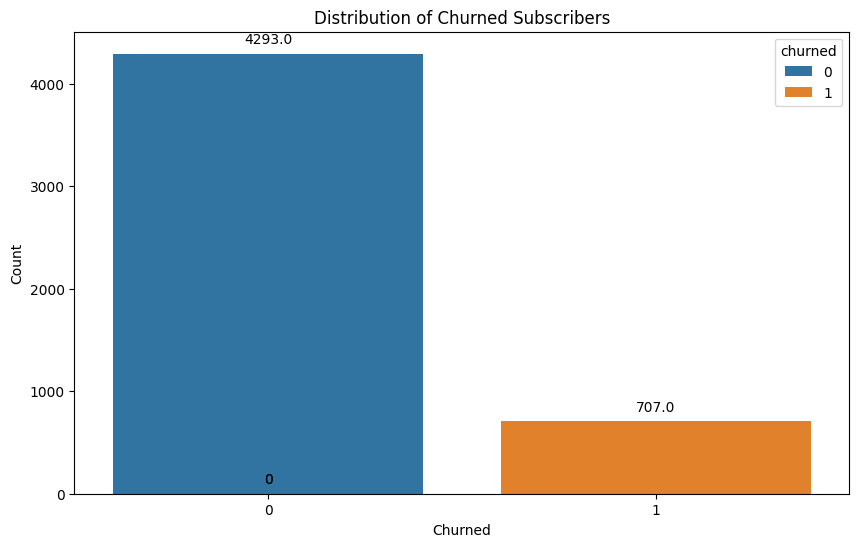

In [11]:
# Distribution of churned subscribers
plt.figure(figsize=(10, 6))

# Plot
ax = sns.countplot(x='churned', data=df, hue='churned')

# Properties
plt.title('Distribution of Churned Subscribers')
plt.xlabel('Churned')
plt.ylabel('Count')

# Add counts
for p in ax.patches:
    ax.annotate(p.get_height(), (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 10), textcoords='offset points')

plt.show()

Given the skew in the predictor variable, let's split the data with the *churned* values being stratified.

In [12]:
from sklearn.model_selection import train_test_split

X = df.drop('churned', axis=1)
y = df['churned']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)

In [13]:
# Show training/testing split
print(f"X_train: {X_train.shape}\n X_test: {X_test.shape}\n y_train: {y_train.shape}\n y_test: {y_test.shape}")

X_train: (3500, 17)
 X_test: (1500, 17)
 y_train: (3500,)
 y_test: (1500,)


## Question 3

* Fit random forest models with a range of tree numbers and evaluate the out-of-bag error for each of these models.
* Plot the resulting oob errors as a function of the number of trees.

*Hint:* since the only thing changing is the number of trees, the `warm_start` flag can be used so that the model just adds more trees to the existing model each time. Use the `set_params` method to update the number of trees.

In [14]:
# Suppress warnings about too few trees from the early models

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [16]:
rf = RandomForestClassifier(oob_score=True, random_state=42)

rf.fit(X_train, y_train)

RandomForestClassifier(oob_score=True, random_state=42)

In [17]:
y_predict = rf.predict(X_test)

print(f"Model accuracy score: {accuracy_score(y_test, y_predict):.3f}")

Model accuracy score: 0.962


The error looks like it has stabilized around 100-150 trees.

In [18]:
# Define the range of tree numbers to inspect
tree_counts = [15, 50, 100, 150, 200]
oob_errors = []

# Loop through each tree count
for n_trees in tree_counts:
    rf_temp = RandomForestClassifier(n_estimators=n_trees, oob_score=True, random_state=42)
    rf_temp.fit(X_train, y_train)
    oob_error = 1 - rf_temp.oob_score_
    oob_errors.append(oob_error)
    print(f"Number of trees: {n_trees}, OOB Error: {oob_error:.4f}")

# Optional: You can store these results in a DataFrame or plot them for better visualization
results_df = pd.DataFrame({'n_estimators': tree_counts, 'oob_error': oob_errors})
print(results_df)

Number of trees: 15, OOB Error: 0.0597
Number of trees: 50, OOB Error: 0.0491
Number of trees: 100, OOB Error: 0.0451
Number of trees: 150, OOB Error: 0.0451
Number of trees: 200, OOB Error: 0.0449
   n_estimators  oob_error
0            15   0.059714
1            50   0.049143
2           100   0.045143
3           150   0.045143
4           200   0.044857


## Question 4

* Repeat question 3 using extra randomized trees (`ExtraTreesClassifier`). Note that the `bootstrap` parameter will have to be set to `True` for this model.
* Compare the out-of-bag errors for the two different types of models.

In [19]:
from sklearn.ensemble import ExtraTreesClassifier

et = ExtraTreesClassifier(bootstrap=True, oob_score=True, random_state=42)
et.fit(X_train, y_train)

ExtraTreesClassifier(bootstrap=True, oob_score=True, random_state=42)

In [20]:
y_predict = et.predict(X_test)

print(f"Model accuracy score: {accuracy_score(y_test, y_predict):.3f}")

Model accuracy score: 0.938


In [21]:
# Loop through each tree count
tree_counts = [15, 50, 100, 150, 200]
oob_errors = []

for n_trees in tree_counts:
    et_temp = ExtraTreesClassifier(bootstrap=True, oob_score=True, random_state=42)
    et_temp.fit(X_train, y_train)
    oob_error = 1 - rf_temp.oob_score_
    oob_errors.append(oob_error)
    print(f"Number of trees: {n_trees}, OOB Error: {oob_error:.4f}")

# Optional: You can store these results in a DataFrame or plot them for better visualization
results_et_df = pd.DataFrame({'n_estimators': tree_counts, 'oob_error': oob_errors})
print(results_et_df)

Number of trees: 15, OOB Error: 0.0449
Number of trees: 50, OOB Error: 0.0449
Number of trees: 100, OOB Error: 0.0449
Number of trees: 150, OOB Error: 0.0449
Number of trees: 200, OOB Error: 0.0449
   n_estimators  oob_error
0            15   0.044857
1            50   0.044857
2           100   0.044857
3           150   0.044857
4           200   0.044857


Combine the two dataframes into a single one for easier plotting.

In [22]:
# Combine error columns in one dataframe
results_df = results_df.merge(results_et_df, on='n_estimators', suffixes=('_rf', '_et'))

The random forest model performs consistently better than the extra randomized trees.

In [23]:
results_df

,n_estimators,oob_error_rf,oob_error_et
0,15,0.059714,0.044857
1,50,0.049143,0.044857
2,100,0.045143,0.044857
3,150,0.045143,0.044857
4,200,0.044857,0.044857


## Question 5

* Select one of the models that performs well and calculate error metrics and a confusion matrix on the test data set.
* Given the distribution of the predicted class, which metric is most important? Which could be deceiving?

In [24]:
from sklearn.metrics import confusion_matrix, classification_report

In [25]:
#
y_pred = rf.predict(X_test)
print(classification_report(y_pred, y_test))

              precision    recall  f1-score   support

           0       0.99      0.96      0.98      1325
           1       0.78      0.94      0.85       175

    accuracy                           0.96      1500
   macro avg       0.89      0.95      0.92      1500
weighted avg       0.97      0.96      0.96      1500



Unsurprisingly, recall is rather poor for the customers who churned (True) class since they are quite small. We are doing better than random guessing, though, as the accuracy is 0.932 (vs 0.85 for random guessing).

## Question 6

* Print or visualize the confusion matrix.
* Plot the ROC-AUC and precision-recall curves.
* Plot the feature importances.

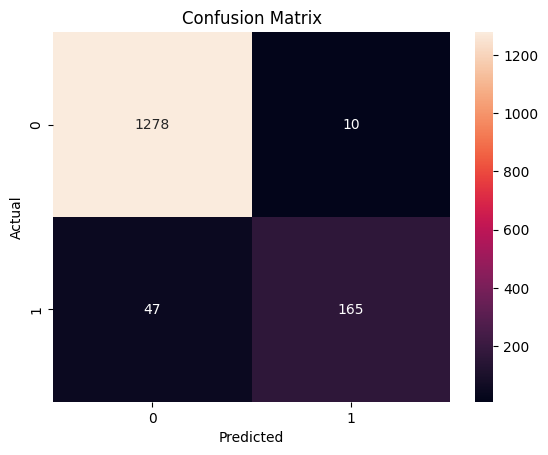

In [26]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d')

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

The ROC-AUC and precision-recall curves.

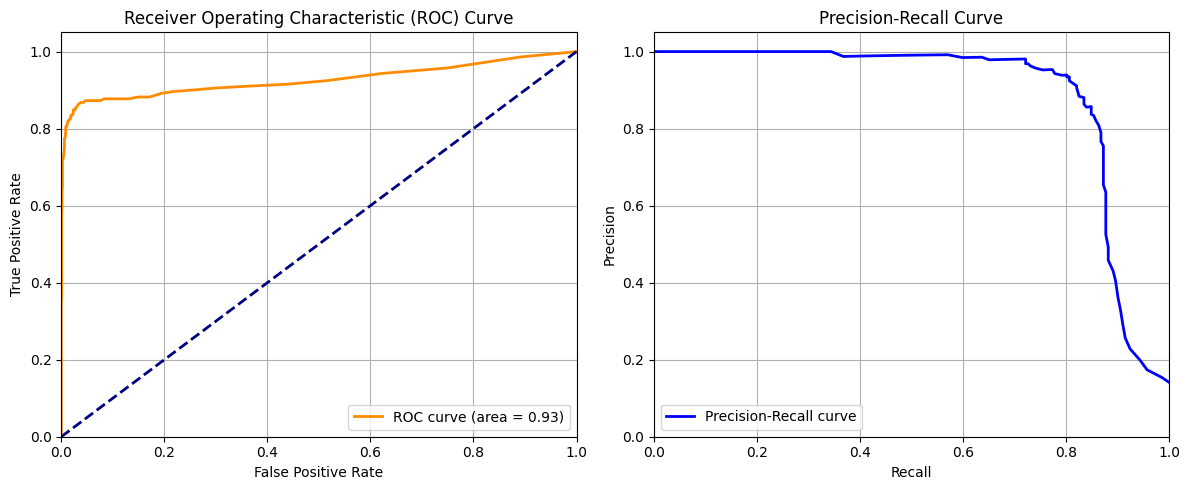

In [27]:
# The ROC-AUC and precision-recall curves.
from sklearn.metrics import roc_curve, auc, precision_recall_curve
import matplotlib.pyplot as plt

# Get predicted probabilities for the positive class (churned=1)
y_probs = rf.predict_proba(X_test)[:, 1]

# --- ROC Curve ---
fpr, tpr, thresholds_roc = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)

# --- Precision-Recall Curve ---
precision, recall, thresholds_pr = precision_recall_curve(y_test, y_probs)

plt.subplot(1, 2, 2)
plt.plot(recall, precision, color='blue', lw=2, label='Precision-Recall curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.grid(True)
plt.legend(loc="lower left")

plt.tight_layout()
plt.show()

The feature importances. Total daily cost is the biggest predictor of customer churn.

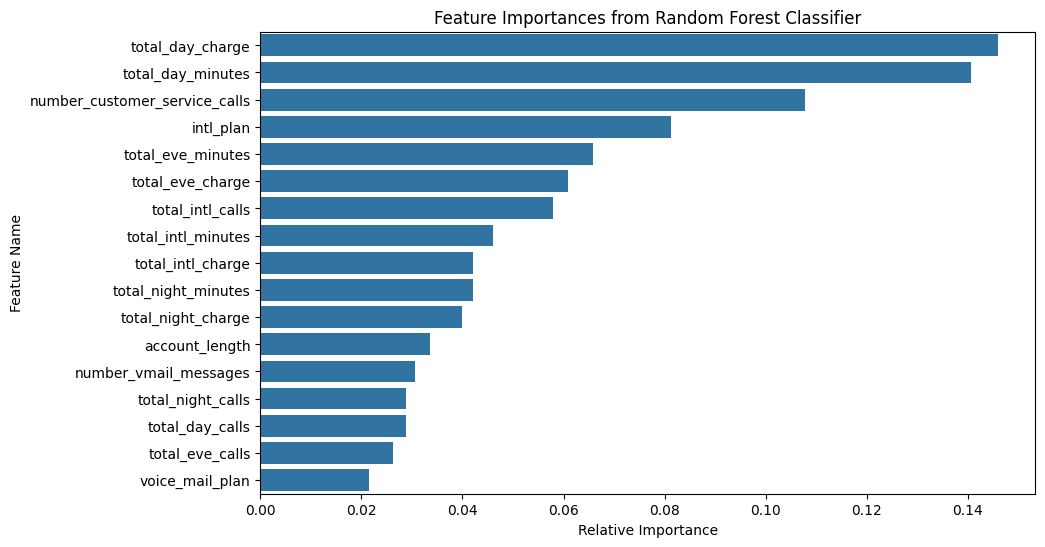

Top 5 most important features:
                          Feature  Importance
6                total_day_charge    0.146095
4               total_day_minutes    0.140686
16  number_customer_service_calls    0.107719
1                       intl_plan    0.081321
7               total_eve_minutes    0.065913


In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importances from the trained Random Forest model
feature_importances = rf.feature_importances_

# Get feature names from the training data (X_train)
feature_names = X_train.columns

# Create a DataFrame for better visualization and sorting
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
})

# Sort the features by importance in descending order
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('Feature Importances from Random Forest Classifier')
plt.xlabel('Relative Importance')
plt.ylabel('Feature Name')
plt.show()

print("Top 5 most important features:")
print(importance_df.head())

# Supplementary Activity

2. Using your own dataset, perform bagging.
3. Using your own dataset, perform boosting (AdaBoost, XGBoost, and etc) and stacking.
4. For stacking, identify the different models you used and their performances vs their performance when stacked.
5. Evaluate the different ensemble learning methods used in this activity.

Dataset: [Network Anomaly Detection Dataset with Labeled and Unlabeled Version](https://www.kaggle.com/datasets/kaiser14/network-anomaly-dataset)

In [29]:
# Import dataframe
df = pd.read_csv("network_dataset_labeled.csv")
df.head()

,timestamp,bandwidth,throughput,congestion,packet_loss,latency,jitter,Routers,Planned route,Network measure,...,Video target,Percentage video occupancy,Bitrate video,Number videos,anomaly_throughput,anomaly_congestion,anomaly_packet_loss,anomaly_latency,anomaly_jitter,anomaly
0,2024-05-11 12:00:15,2,2.15,0.38,0.0,6.58,0.52,up xrv6,Best effort,S1,...,NaN,0,0,0,0,0,0,0,0,0
1,2024-05-11 12:00:43,2,2.16,0.12,0.0,5.36,0.34,up xrv6,Best effort,S1,...,NaN,0,0,0,0,0,0,0,0,0
2,2024-05-11 12:01:12,2,2.00,0.08,0.0,6.29,0.23,up xrv6,Best effort,S1,...,NaN,0,0,0,0,0,0,0,0,0
3,2024-05-11 12:01:40,2,2.07,0.07,0.0,5.91,0.51,up xrv6,Best effort,S1,...,NaN,0,0,0,0,0,0,0,0,0
4,2024-05-11 12:02:08,2,2.40,0.08,0.0,5.81,0.71,up xrv6,Best effort,S1,...,NaN,0,0,0,0,0,0,0,0,0


Explore Dataset

In [30]:
# df shape
df.shape

(1001, 21)

In [31]:
# df info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001 entries, 0 to 1000
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   timestamp                   1001 non-null   object 
 1   bandwidth                   1001 non-null   int64  
 2   throughput                  1001 non-null   float64
 3   congestion                  1001 non-null   float64
 4   packet_loss                 1001 non-null   float64
 5   latency                     1001 non-null   float64
 6   jitter                      1001 non-null   float64
 7   Routers                     1001 non-null   object 
 8   Planned route               1001 non-null   object 
 9   Network measure             1001 non-null   object 
 10  Network target              1001 non-null   object 
 11  Video target                701 non-null    object 
 12  Percentage video occupancy  1001 non-null   int64  
 13  Bitrate video               1001 

In [65]:
df.iloc[0]

,200
timestamp,2024-05-11 14:23:59
bandwidth,2
throughput,1.43
congestion,0.1
packet_loss,0.0
latency,5.67
jitter,0.59
Routers,up xrv6
Planned route,Best effort
Network measure,S1


Check missing values

In [32]:
df.isna().sum()

,0
timestamp,0
bandwidth,0
throughput,0
congestion,0
packet_loss,0
latency,0
jitter,0
Routers,0
Planned route,0
Network measure,0


In [33]:
# Drop missing values
df.dropna(inplace=True)

In [34]:
df.columns

Index(['timestamp', 'bandwidth', 'throughput', 'congestion', 'packet_loss',
       'latency', 'jitter', 'Routers', 'Planned route', 'Network measure',
       'Network target', 'Video target', 'Percentage video occupancy',
       'Bitrate video', 'Number videos', 'anomaly_throughput',
       'anomaly_congestion', 'anomaly_packet_loss', 'anomaly_latency',
       'anomaly_jitter', 'anomaly'],
      dtype='object')

Define features and target columns

In [35]:
target_col = "anomaly"

# Columns to drop from features
cols_to_drop = [
    target_col,
    'timestamp',
    'anomaly_throughput',
    'anomaly_congestion',
    'anomaly_packet_loss',
    'anomaly_latency',
    'anomaly_jitter',
    'Routers',
    'Planned route',
    'Network measure',
    'Network target',
    'Video target'
]

df_features = df.drop(columns=cols_to_drop)
df_target = df[target_col]

In [36]:
df_target.head()

,anomaly
200,0
201,0
202,0
203,0
204,0


Preprocessing

In [37]:
dummies_df = pd.get_dummies(df_target.values)

In [49]:
dummies_df

,0,1
0,True,False
1,True,False
2,True,False
3,True,False
4,True,False
...,...,...
696,True,False
697,True,False
698,True,False
699,True,False


In [50]:
from sklearn.preprocessing import LabelEncoder
import numpy as np

encoder = LabelEncoder()
label_df = encoder.fit_transform(df_target)

In [51]:
label_df[:20]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

Feature Engineering

In [40]:
# Feature Engineering
df_features

,bandwidth,throughput,congestion,packet_loss,latency,jitter,Percentage video occupancy,Bitrate video,Number videos
200,2,1.43,0.10,0.0,5.67,0.59,0,0,1
201,2,1.62,0.08,0.0,5.64,0.40,0,0,1
202,2,2.02,0.09,0.0,5.91,0.57,0,0,1
203,2,2.06,0.09,0.0,6.99,0.22,0,0,1
204,2,1.69,0.08,0.0,5.77,0.55,0,0,1
...,...,...,...,...,...,...,...,...,...
996,2,2.91,5.55,10.0,10.59,0.83,10,167,1
997,2,1.91,9.36,7.5,10.46,0.79,10,167,1
998,2,1.45,15.86,0.0,10.49,1.35,10,167,1
999,2,3.10,9.96,10.0,10.36,1.31,10,167,1


In [41]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_features = scaler.fit_transform(df_features)

In [52]:
feature_column_names = df.drop(columns=cols_to_drop).columns

df_copy = pd.DataFrame(df_features, columns=feature_column_names)
df_copy["target"] = label_df

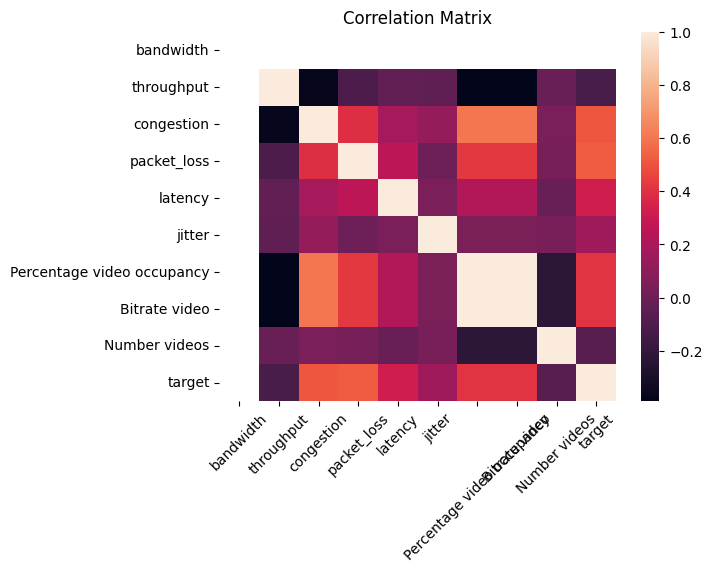

In [56]:
corr = df_copy.corr()
sns.heatmap(corr)

plt.title("Correlation Matrix")
plt.xticks(rotation=45)

plt.show()

Define correlated columns

In [57]:
corr[np.abs(corr["target"]) > 0.5]["target"]

,target
congestion,0.507026
packet_loss,0.524376
target,1.000000


In [58]:
high_corr_columns = corr[np.abs(corr["target"]) > 0.5]["target"].drop(index=["target"]).index.values

In [59]:
high_corr_columns

array(['congestion', 'packet_loss'], dtype=object)

In [61]:
df_features = pd.DataFrame(df_features, columns=feature_column_names)
df_features = df_features[high_corr_columns]
df_features.head()

,congestion,packet_loss
0,-1.009058,-0.676244
1,-1.009653,-0.676244
2,-1.009356,-0.676244
3,-1.009356,-0.676244
4,-1.009653,-0.676244


In [62]:
# Train Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df_features, label_df,
                                        test_size = 0.3, random_state = 42)

### Ensemble Learning Methods

In [81]:
# Define models
# Bagging
from sklearn.ensemble import RandomForestClassifier

# Boosting
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier

# Stacked (RF, Ada, XG)
from sklearn.ensemble import VotingClassifier

# Define essential functions
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score, roc_curve
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

### Bagging

In [70]:
rf = RandomForestClassifier()
rf.fit(X_train, y_train)

RandomForestClassifier()

In [77]:
rf_pred = rf.predict(X_test)

# Model accuracy
rf_acc = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)

print("Accuracy Score: ", rf_acc)
print("Precision Score: ", rf_precision)
print("Recall Score: ", rf_recall)

Accuracy Score:  0.8909952606635071
Precision Score:  0.6363636363636364
Recall Score:  0.4827586206896552


In [76]:
# Classification Report
rf_classrep = classification_report(y_test, rf_pred)
print(rf_classrep)

              precision    recall  f1-score   support

           0       0.92      0.96      0.94       182
           1       0.64      0.48      0.55        29

    accuracy                           0.89       211
   macro avg       0.78      0.72      0.74       211
weighted avg       0.88      0.89      0.88       211



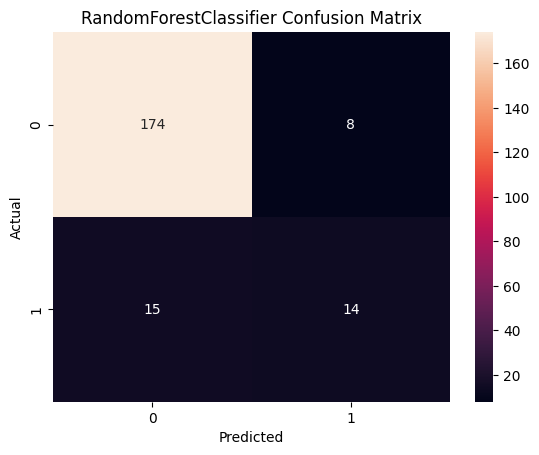

In [75]:
# Confusion Matrix
rf_conf = confusion_matrix(y_test, rf_pred)

ax = sns.heatmap(rf_conf, annot=True, fmt='d')
plt.title("RandomForestClassifier Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [104]:
# ROC AUC and Curve

rf_rocauc = roc_auc_score(y_test, rf_pred, multi_class="ovr")
rf_roccurve = roc_curve(y_test, rf_pred)

print("ROC AUC Score: ", rf_rocauc)
print("ROC Curve Score: ", rf_roccurve)

ROC AUC Score:  0.7194012883668056
ROC Curve Score:  (array([0.        , 0.04395604, 1.        ]), array([0.        , 0.48275862, 1.        ]), array([inf,  1.,  0.]))


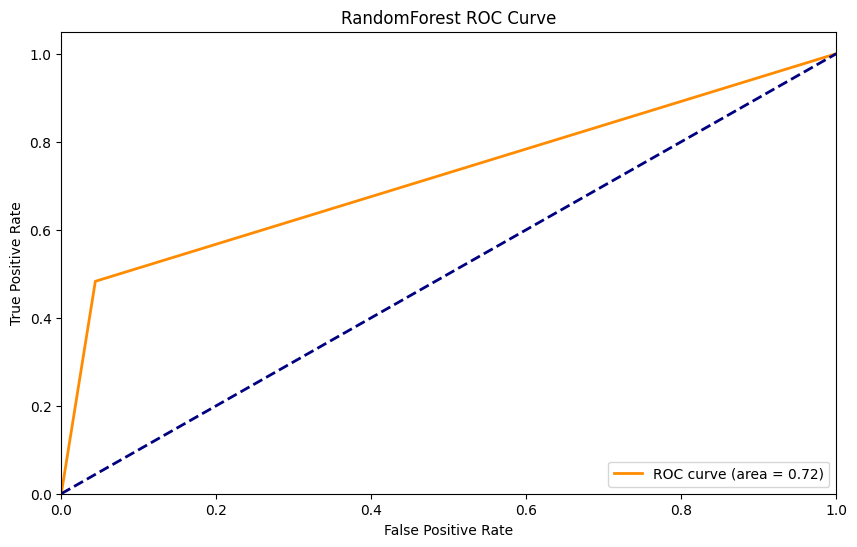

In [107]:
# ROC curve
plt.figure(figsize=(10, 6))

plt.plot(rf_roccurve[0], rf_roccurve[1], color='darkorange', lw=2, label=f'ROC curve (area = {rf_rocauc:.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('RandomForest ROC Curve')
plt.legend(loc="lower right")

plt.show()

### Boosting

AdaBoost

In [82]:
ada = AdaBoostClassifier()
ada.fit(X_train, y_train)

AdaBoostClassifier()

In [84]:
ada_pred = rf.predict(X_test)

# Model accuracy
ada_acc = accuracy_score(y_test, ada_pred)
ada_precision = precision_score(y_test, ada_pred)
ada_recall = recall_score(y_test, ada_pred)

print("Accuracy Score: ", ada_acc)
print("Precision Score: ", ada_precision)
print("Recall Score: ", ada_recall)

Accuracy Score:  0.8909952606635071
Precision Score:  0.6363636363636364
Recall Score:  0.4827586206896552


In [85]:
# Classification Report
ada_classrep = classification_report(y_test, ada_pred)
print(ada_classrep)

              precision    recall  f1-score   support

           0       0.92      0.96      0.94       182
           1       0.64      0.48      0.55        29

    accuracy                           0.89       211
   macro avg       0.78      0.72      0.74       211
weighted avg       0.88      0.89      0.88       211



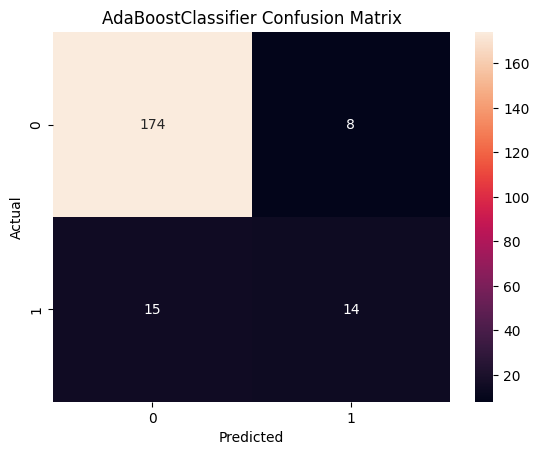

In [86]:
# Confusion Matrix
ada_conf = confusion_matrix(y_test, ada_pred)

ax = sns.heatmap(ada_conf, annot=True, fmt='d')
plt.title("AdaBoostClassifier Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [108]:
# ROC AUC and Curve

ada_rocauc = roc_auc_score(y_test, ada_pred, multi_class="ovr")
ada_roccurve = roc_curve(y_test, ada_pred)

print("ROC AUC Score: ", ada_rocauc)
print("ROC Curve Score: ", ada_roccurve)

ROC AUC Score:  0.7194012883668056
ROC Curve Score:  (array([0.        , 0.04395604, 1.        ]), array([0.        , 0.48275862, 1.        ]), array([inf,  1.,  0.]))


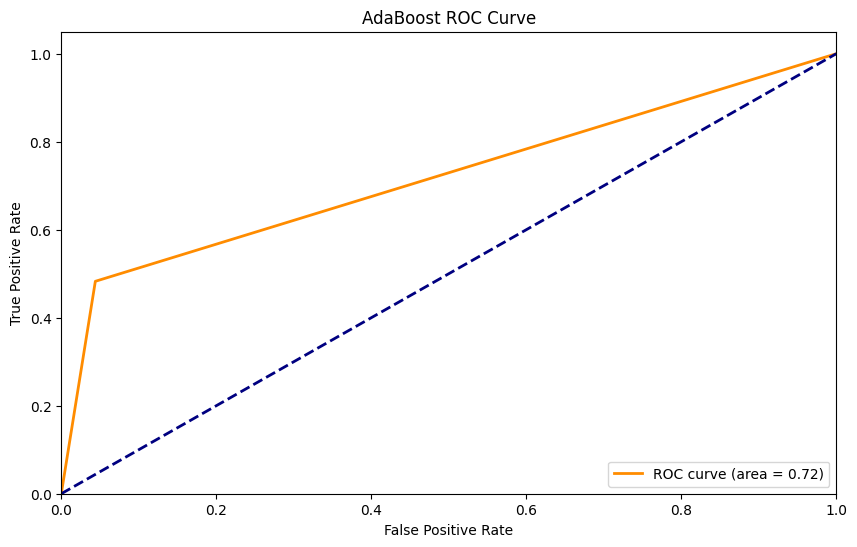

In [110]:
# ROC curve
plt.figure(figsize=(10, 6))

plt.plot(ada_roccurve[0], ada_roccurve[1], color='darkorange', lw=2, label=f'ROC curve (area = {ada_rocauc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('AdaBoost ROC Curve')
plt.legend(loc="lower right")

plt.show()

Gradient Boosting

In [89]:
xgb = GradientBoostingClassifier()
xgb.fit(X_train, y_train)

GradientBoostingClassifier()

In [91]:
xgb_pred = xgb.predict(X_test)

# Model accuracy
xgb_acc = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred)
xgb_recall = recall_score(y_test, xgb_pred)

print("Accuracy Score: ", xgb_acc)
print("Precision Score: ", xgb_precision)
print("Recall Score: ", xgb_recall)

Accuracy Score:  0.9052132701421801
Precision Score:  0.6956521739130435
Recall Score:  0.5517241379310345


In [93]:
# Classification Report
xgb_classrep = classification_report(y_test, xgb_pred)
print(xgb_classrep)

              precision    recall  f1-score   support

           0       0.93      0.96      0.95       182
           1       0.70      0.55      0.62        29

    accuracy                           0.91       211
   macro avg       0.81      0.76      0.78       211
weighted avg       0.90      0.91      0.90       211



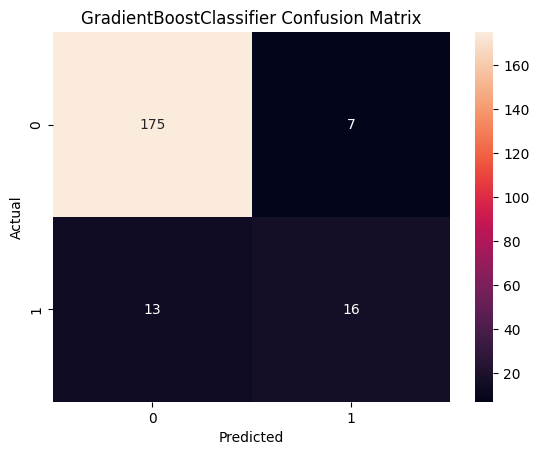

In [95]:
# Confusion Matrix
xgb_conf = confusion_matrix(y_test, xgb_pred)

ax = sns.heatmap(xgb_conf, annot=True, fmt='d')
plt.title("GradientBoostClassifier Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [112]:
# ROC AUC and Curve

xgb_rocauc = roc_auc_score(y_test, xgb_pred, multi_class="ovr")
xgb_roccurve = roc_curve(y_test, xgb_pred)

print("ROC AUC Score: ", xgb_rocauc)
print("ROC Curve Score: ", xgb_roccurve)

ROC AUC Score:  0.756631299734748
ROC Curve Score:  (array([0.        , 0.03846154, 1.        ]), array([0.        , 0.55172414, 1.        ]), array([inf,  1.,  0.]))


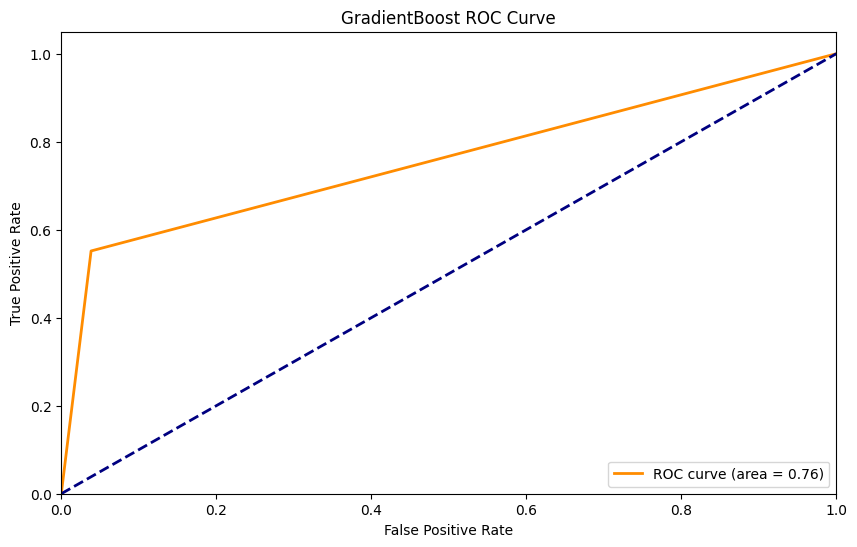

In [113]:
# ROC curve
plt.figure(figsize=(10, 6))

plt.plot(xgb_roccurve[0], xgb_roccurve[1], color='darkorange', lw=2, label=f'ROC curve (area = {xgb_rocauc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('GradientBoost ROC Curve')
plt.legend(loc="lower right")

plt.show()

### Stacking

In [97]:
estimators = [("RandomForest", rf), ("ADABoost", ada), ("XGBoost", xgb)]

VC = VotingClassifier(estimators, voting='soft')
VC = VC.fit(X_train, y_train)

In [100]:
VC_pred = VC.predict(X_test)

# Model Accuracy
VC_acc = accuracy_score(y_test, VC_pred)
VC_precision = precision_score(y_test, VC_pred)
VC_recall = recall_score(y_test, VC_pred)

print("Accuracy Score: ", VC_acc)
print("Precision Score: ", VC_precision)
print("Recall Score: ", VC_recall)

Accuracy Score:  0.9052132701421801
Precision Score:  0.6956521739130435
Recall Score:  0.5517241379310345


In [101]:
# Classification Report
VC_classrep = classification_report(y_test, VC_pred)
print(VC_classrep)

              precision    recall  f1-score   support

           0       0.93      0.96      0.95       182
           1       0.70      0.55      0.62        29

    accuracy                           0.91       211
   macro avg       0.81      0.76      0.78       211
weighted avg       0.90      0.91      0.90       211



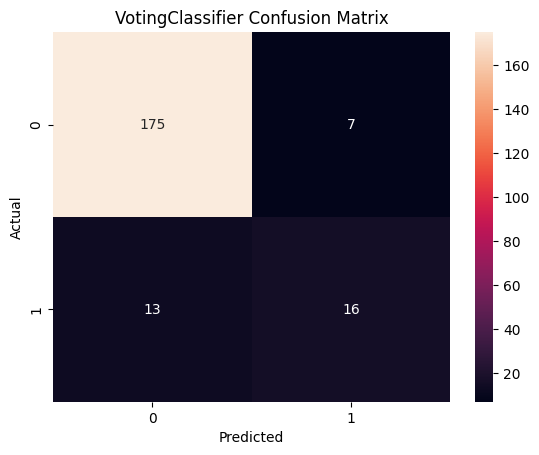

In [102]:
# Confusion Matrix
VC_conf = confusion_matrix(y_test, VC_pred)

ax = sns.heatmap(VC_conf, annot=True, fmt='d')
plt.title("VotingClassifier Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [114]:
# ROC AUC and Curve

VC_rocauc = roc_auc_score(y_test, VC_pred, multi_class="ovr")
VC_roccurve = roc_curve(y_test, VC_pred)

print("ROC AUC Score: ", VC_rocauc)
print("ROC Curve Score: ", VC_roccurve)

ROC AUC Score:  0.756631299734748
ROC Curve Score:  (array([0.        , 0.03846154, 1.        ]), array([0.        , 0.55172414, 1.        ]), array([inf,  1.,  0.]))


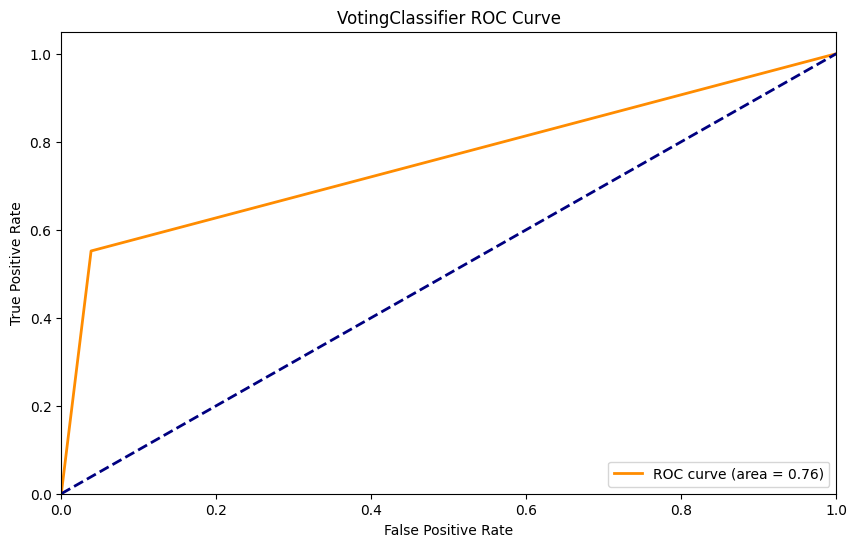

In [116]:
# ROC curve
plt.figure(figsize=(10, 6))

plt.plot(VC_roccurve[0], VC_roccurve[1], color='darkorange', lw=2, label=f'ROC curve (area = {VC_rocauc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('VotingClassifier ROC Curve')
plt.legend(loc="lower right")

plt.show()

### Ensemble Learning Methods Evaluation

Upon evaluating the performance of the different ensemble learning models, the GradientBoosting Classifier and the VotingClassifier come out as the top performers, both achieving an accuracy of approximately 0.905, a precision of about 0.696, a recall of around 0.552, and an ROC AUC score of approximately 0.757. The RandomForest Classifier and AdaBoost Classifier showed slightly lower, but identical, performance with an accuracy of about 0.891, a precision of roughly 0.636, a recall of about 0.483, and an ROC AUC of approximately 0.719.

These results indicate that for anomaly detection task, the boosting method provided a better balance of identifying anomalies while maintaining precision and overall accuracy. The stacking method can also be applied in this task as it matched the boosting method.

## Conclusion

This activity involved a comprehensive demonstration of ensemble learning methods, where we applied them in telecom churn data and anomaly detection. The process began with initial data loading and exploration and preprocessing steps including handling missing values, identifying relevant features, and converting categorical data. I have also discovered how Feature engineering works. It involved scaling the numerical features and selecting highly correlated features, which is essential in building accurate models. Various ensemble models were then implemented in the datasets, namely Random Forest or the bagging method, Adaptive Boost and Gradient Boosting or boosting methods, and VotingClassifier or the stacking method. Each model's performance was evaluated using metrics such as accuracy, classification reports, confusion matrices, and ROC AUC curves. These steps were made in the procedure and supplementary activity.

The supplementary activity involved a network anomaly detection model, trained using a network anomaly dataset. Its results show how the Gradient Boosting and the Voting Classifier performed greatly among other models, having higher accuracy, precision, recall, and ROC AUC scores.

Therefore, the activity successfully demonstrated the concepts and implementation of ensemble learning methods.